# День 08. Упражнение 02
# Мульти-классовая классификация. One-hot кодирование. Случайный лес

## 0. Импорты

In [457]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OneHotEncoder
from sklearn.multiclass import OneVsRestClassifier

## 1. Предобработка


1. Прочитай файл [`checker-submits.csv`](https://drive.google.com/file/d/14voc4fNJZiLEFaZyd8nEG-lQt5JjatYw/view?usp=sharing).

In [458]:
df = pd.read_csv("../data/checker_submits.csv")
df.head(3)

,uid,labname,numTrials,timestamp
0,user_4,project1,1,2020-04-17 05:19:02.744528
1,user_4,project1,2,2020-04-17 05:22:45.549397
2,user_4,project1,3,2020-04-17 05:34:24.422370


In [459]:
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df = df.dropna()

2. Создай DataFrame `df` с колонками: `uid`, `labname`, `numTrials`, `hour`, `dayofweek`, где `hour` извлекается из `timestamp`, а также `dayofweek` (`0` — понедельник, `6` — воскресенье). Мы будем пытаться предсказать день недели, имея данные о том, какой пользователь сделал коммит, для какой лабораторной, в какой час и с какой попытки.

In [460]:
df["hour"] = df["timestamp"].dt.hour
df["dayofweek"] = df["timestamp"].dt.weekday
df.head(3)

,uid,labname,numTrials,timestamp,hour,dayofweek
0,user_4,project1,1,2020-04-17 05:19:02.744528,5,4
1,user_4,project1,2,2020-04-17 05:22:45.549397,5,4
2,user_4,project1,3,2020-04-17 05:34:24.422370,5,4


In [461]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1686 entries, 0 to 1685
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   uid        1686 non-null   str           
 1   labname    1686 non-null   str           
 2   numTrials  1686 non-null   int64         
 3   timestamp  1686 non-null   datetime64[us]
 4   hour       1686 non-null   int32         
 5   dayofweek  1686 non-null   int32         
dtypes: datetime64[us](1), int32(2), int64(1), str(2)
memory usage: 66.0 KB


3. С помощью `OneHotEncoder()` преобразуй категориальные признаки, затем удали из DataFrame исходные столбцы.

In [462]:
# sparse_output=False заставляет энкодер выдать стандартный массив чисел Numpy, который Pandas легко переваривает, иначе получим специальный объект сжатой памяти — разреженную матрицу SciPy
# Метод .set_output(transform="pandas") обладает высшим приоритетом. Он полностью перехватывает управление и меняет поведение метода .fit_transform().После этого .fit_transform() больше НЕ возвращает массив NumPy. Он сразу же отдаёт готовый DataFrame с правильными именами колонок.
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
# encoded_features_X = encoder.fit_transform(df[["uid", "labname"]])
# df = df.join(encoded_features_X)
#
df = df.join(encoder.fit_transform(df[["uid", "labname"]]))

df.head(3)

,uid,labname,numTrials,timestamp,hour,dayofweek,uid_user_0,uid_user_1,uid_user_10,uid_user_11,...,labname_lab02,labname_lab03,labname_lab03s,labname_lab05s,labname_laba04,labname_laba04s,labname_laba05,labname_laba06,labname_laba06s,labname_project1
0,user_4,project1,1,2020-04-17 05:19:02.744528,5,4,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,user_4,project1,2,2020-04-17 05:22:45.549397,5,4,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,user_4,project1,3,2020-04-17 05:34:24.422370,5,4,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [463]:
df.drop(columns=["uid", "labname", "timestamp"], inplace=True, errors="ignore")
df.head(3)

,numTrials,hour,dayofweek,uid_user_0,uid_user_1,uid_user_10,uid_user_11,uid_user_12,uid_user_13,uid_user_14,...,labname_lab02,labname_lab03,labname_lab03s,labname_lab05s,labname_laba04,labname_laba04s,labname_laba05,labname_laba06,labname_laba06s,labname_project1
0,1,5,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2,5,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,3,5,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


4. Используй `StandardScaler()` и нормализуй числовые признаки.

In [464]:
scaler = StandardScaler()
df[["numTrials", "hour"]] = scaler.fit_transform(df[["numTrials", "hour"]])
df.head(3)

,numTrials,hour,dayofweek,uid_user_0,uid_user_1,uid_user_10,uid_user_11,uid_user_12,uid_user_13,uid_user_14,...,labname_lab02,labname_lab03,labname_lab03s,labname_lab05s,labname_laba04,labname_laba04s,labname_laba05,labname_laba06,labname_laba06s,labname_project1
0,-0.788667,-2.562352,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-0.756764,-2.562352,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-0.724861,-2.562352,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


5. Сохрани DataFrame как `dayofweek.csv`.

In [465]:
df.to_csv("../data/dayofweek.csv", index=False)

6. Перед тем как пробовать разные алгоритмы, вычисли точность наивного алгоритма — того, который предсказывает всё как самый частый класс.

In [466]:
df_info = df["dayofweek"].value_counts()
df_info

dayofweek
3    396
6    356
1    274
5    271
2    149
0    136
4    104
Name: count, dtype: int64

In [467]:
naive_accuracy = df["dayofweek"].value_counts().max() / df.shape[0]
print(naive_accuracy)

0.23487544483985764


## 2. Алгоритмы


### a. Логистическая регрессия

1. Обучи логистическую регрессию; для базовой модели используй `random_state=21`, `fit_intercept=False`.

In [468]:
df_multiclass = pd.read_csv("../data/dayofweek.csv")
df_multiclass.head(3)

,numTrials,hour,dayofweek,uid_user_0,uid_user_1,uid_user_10,uid_user_11,uid_user_12,uid_user_13,uid_user_14,...,labname_lab02,labname_lab03,labname_lab03s,labname_lab05s,labname_laba04,labname_laba04s,labname_laba05,labname_laba06,labname_laba06s,labname_project1
0,-0.788667,-2.562352,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-0.756764,-2.562352,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-0.724861,-2.562352,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [469]:
y = df_multiclass["dayofweek"]
X = df_multiclass.drop(columns=["dayofweek"])

In [470]:
logRegMulti = LogisticRegression(
    random_state=21,
    fit_intercept=False,
    solver="lbfgs",
    max_iter=2000,  # multi_class='ovr'
)
logRegMultiOVR = OneVsRestClassifier(logRegMulti)
logRegMultiOVR.fit(X, y)
# без OneVsRestClassifier над моделью лидер был другой и причиной было то, что параметр multi_class='ovr' был убран в текущей версии scikit-learn, в которой модель по умолчанию обучается в режиме multinomial (глобальная оптимизация всех 7 дней одновременно), в старых версиях по умолчанию для многоклассовых задач использовался режим multi_class='ovr' (One-vs-Rest).В режиме ovr математика весов считается совершенно по-другому: строятся 7 независимых бинарных классификаторов (Понедельник против всех, Вторник против всех и т.д.). На старой версии в режиме ovr признак labname_code_rvw как раз и выходит на первое место.
# OneVsRestClassifier запускает обучение LogisticRegression 7 раз подряд (по одному разу для каждого дня недели)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LogisticRegre...ndom_state=21)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",False
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default

2. Вычисли точность (accuracy).

In [471]:
y_pred = logRegMultiOVR.predict(X)
full_accuracy = accuracy_score(y, y_pred)
full_accuracy

0.6209964412811388

3. Напиши функцию, которая строит график (`barh`), принимая коэффициенты обученной модели, имена признаков и количество `top-n` наиболее важных признаков для отображения.
4. Построй график (`barh`) для базовой модели с 10 самыми важными признаками (по абсолютному значению) для обученной модели.
5. Помни, что это мульти-классовая классификация, и `coef_` возвращает матрицу — чтобы вычислить важность признака, нужно просуммировать все индивидуальные значения важности этого признака для всех целевых классов.

In [ ]:
logReg_coef_matrix = np.array(
    [estimator.coef_[0] for estimator in logRegMultiOVR.estimators_]
)
# importance_df = pd.DataFrame(
#     index=X.columns,
#     data=np.sum(np.abs(logReg_coef_matrix), axis=0),
#     columns=["Важность признаков"],
# ).nlargest(10, "Важность признаков")

# print(importance_df)

3. Напиши функцию, которая строит график (`barh`), принимая коэффициенты обученной модели, имена признаков и количество `top-n` наиболее важных признаков для отображения.

In [473]:
def draw_barh_for_feature_importances(coef, feature_names, top_n=10):
    df = pd.DataFrame(
        index=feature_names,
        data=np.sum(np.abs(coef), axis=0),
        columns=["Важность признаков"],
    ).nlargest(
        top_n, "Важность признаков"
    )  # # <--- сначала было .sort_values(by="Важность признаков", ascending=False).head(top_n)

    plt.figure(figsize=(10, 5))
    # Переворачиваем срез [::-1], чтобы самый важный признак на графике был НАВЕРХУ
    plt.barh(
        df.index[::-1],
        df["Важность признаков"][::-1],
    )
    plt.xlabel("Суммарная абсолютная важность (Сумма |weights|)", fontsize=9)
    plt.ylabel("Название признака", fontsize=9)
    plt.title(
        f"Топ-{top_n} наиболее важных признаков",
        fontsize=12,
    )
    plt.grid(True, axis="x", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()
    return df

4. Построй график (`barh`) для базовой модели с 10 самыми важными признаками (по абсолютному значению) для обученной модели.
5. Помни, что это мульти-классовая классификация, и `coef_` возвращает матрицу — чтобы вычислить важность признака, нужно просуммировать все индивидуальные значения важности этого признака для всех целевых классов.

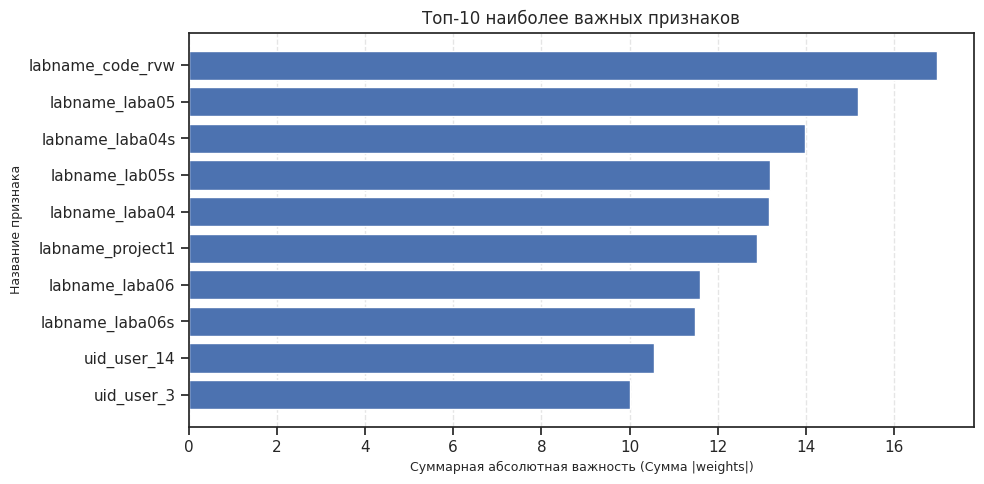

In [474]:
df = draw_barh_for_feature_importances(logReg_coef_matrix, X.columns)

In [475]:
df

,Важность признаков
labname_code_rvw,16.967151
labname_laba05,15.181696
labname_laba04s,13.980694
labname_lab05s,13.181330
labname_laba04,13.155188
labname_project1,12.894855
labname_laba06,11.599447
labname_laba06s,11.491841
uid_user_14,10.548929
uid_user_3,10.007147


### b. SVC

1. Обучи модель `SVC`; для базовой модели используй параметры `kernel='linear'`, `probability=True`, `random_state=21`.
2. Попробуй разные ядра, вычисли точности.
3. Построй график (`barh`) для базовой модели с 10 самыми важными признаками (по абсолютному значению) для обученной модели с линейным ядром.*

*По умолчанию SVC использует стратегию “one vs one” для классификации, поэтому в `coef_` возвращает матрицу. Чтобы вычислить важность признака, нужно использовать [OneVsRestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html) поверх SVC и просуммировать все индивидуальные значения важности признака для всех целевых классов.

In [476]:
model_svc_multi = SVC(kernel="linear", random_state=21, probability=True)
model_svc_multi_OvsRC = OneVsRestClassifier(model_svc_multi)
model_svc_multi_OvsRC.fit(X, y)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",SVC(kernel='l...ndom_state=21)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001


In [477]:
y_pred_svc = model_svc_multi_OvsRC.predict(X)
accuracy_svc = accuracy_score(y, y_pred_svc)
accuracy_svc

0.6115065243179122

In [478]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
accuracy_history = {}
trained_models = {}

for k in kernels:
    model_svc_multi_OvsRC = OneVsRestClassifier(
        SVC(kernel=k, probability=True, random_state=21)
    )
    model_svc_multi_OvsRC.fit(X, y)
    y_pred_svc = model_svc_multi_OvsRC.predict(X)
    acc = accuracy_score(y, y_pred_svc)
    accuracy_history[k] = acc
    trained_models[k] = model_svc_multi_OvsRC

print(accuracy_history)
highest_accuracy = max(accuracy_history.values())
best_kernels = [k for k, v in accuracy_history.items() if v == highest_accuracy]
print(f"Наилучшая точность для модели SVC: {highest_accuracy}")
print(f"Ядро с такой точностью: {', '.join(best_kernels)}")

{'linear': 0.6115065243179122, 'poly': 0.8653618030842231, 'rbf': 0.8641755634638197, 'sigmoid': 0.3499406880189798}
Наилучшая точность для модели SVC: 0.8653618030842231
Ядро с такой точностью: poly


In [479]:
# trained_models

### c. Дерево решений

1. Обучи `DecisionTreeClassifier`; для базовой модели используй `max_depth=4`, `random_state=21`.
2. Попробуй разные значения `max_depth`, вычисли точности.
3. Построй график (`barh`) для базовой модели с 10 самыми важными признаками (по абсолютному значению) для обученной модели, используя написанную функцию.

### d. Случайный лес

В реальной жизни лес состоит из множества деревьев. То же самое и в машинном обучении: случайный лес — это набор отдельных деревьев решений (подробнее см. документацию).

1. Обучи `RandomForestClassifier`; для базовой модели используй параметры `n_estimators=100`, `max_depth=25`, `random_state=21`.
2. Попробуй разные значения `max_depth` и `n_estimators`, вычисли точности.
3. Построй график (`barh`) для базовой модели с 10 самыми важными признаками (по абсолютному значению) для обученной модели, используя написанную функцию.